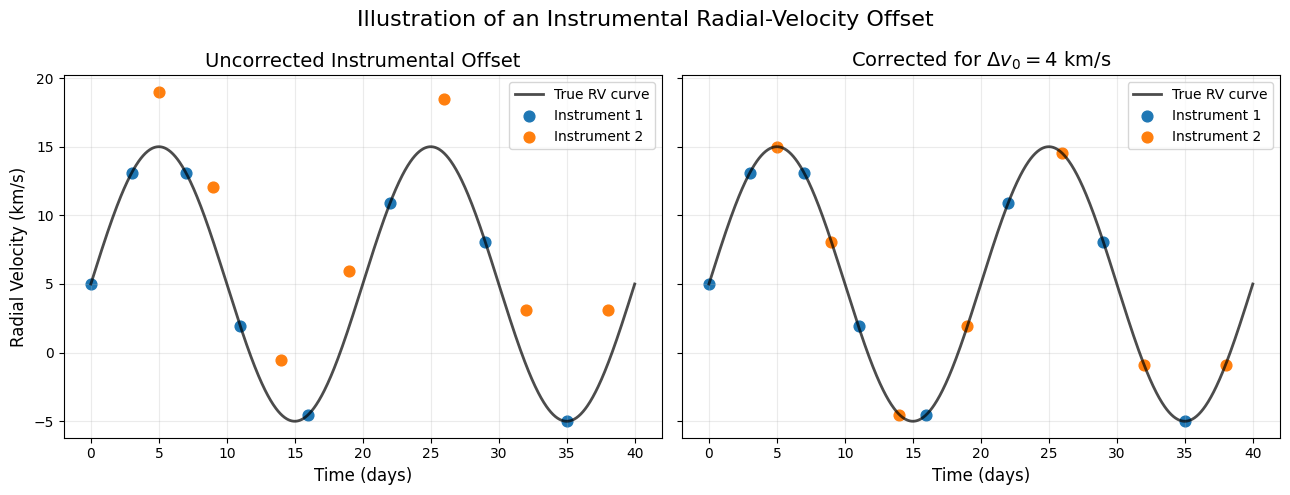

In [9]:
import numpy as np
import matplotlib.pyplot as plt

P = 20.0
K = 10.0
v0 = 5.0
offset = 4.0

def rv_model(t):
    return v0 + K * np.sin(2 * np.pi * t / P)

hecto_times = np.array([0, 3, 7, 11, 16, 22, 29, 35])
apogee_times = np.array([5, 9, 14, 19, 26, 32, 38])

hecto_rv = rv_model(hecto_times)
apogee_rv = rv_model(apogee_times) + offset

t_model = np.linspace(0, 40, 1000)
rv_curve = rv_model(t_model)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

ax = axes[0]

ax.plot(
    t_model,
    rv_curve,
    color="black",
    linewidth=2,
    alpha=0.7,
    label="True RV curve"
)

ax.scatter(
    hecto_times,
    hecto_rv,
    marker="o",
    s=60,
    label="Instrument 1"
)

ax.scatter(
    apogee_times,
    apogee_rv,
    marker="o",
    s=60,
    label="Instrument 2"
)

ax.set_title("Uncorrected Instrumental Offset", fontsize=14)
ax.set_xlabel("Time (days)", fontsize=12)
ax.set_ylabel("Radial Velocity (km/s)", fontsize=12)
ax.legend()
ax.grid(alpha=0.25)

ax = axes[1]

ax.plot(
    t_model,
    rv_curve,
    color="black",
    linewidth=2,
    alpha=0.7,
    label="True RV curve"
)

ax.scatter(
    hecto_times,
    hecto_rv,
    marker="o",
    s=60,
    label="Instrument 1"
)

ax.scatter(
    apogee_times,
    apogee_rv - offset,
    marker="o",
    s=60,
    label="Instrument 2"
)

ax.set_title(r"Corrected for $\Delta v_0 = 4$ km/s", fontsize=14)
ax.set_xlabel("Time (days)", fontsize=12)
ax.legend()
ax.grid(alpha=0.25)

fig.suptitle(
    "Illustration of an Instrumental Radial-Velocity Offset",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "instrumental_offset_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()